In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from PIL import Image
import base64
import numpy as np


In [8]:
%pip install -q groq python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [9]:
# load variables from dotenv file
from dotenv import load_dotenv
from groq import Groq
load_dotenv()

# Read api key
my_api_key = os.getenv("GROQ_API_KEY")

# Check whether the key was loaded
if not my_api_key:
    raise ValueError("GROQ_API_KEY nahi mili. Apni .env file check karo.")

# Create Groq client
client = Groq(api_key=my_api_key)

print("Groq client successfully initialized!")

Groq client successfully initialized!


In [10]:
from groq import Groq

my_api_key = os.getenv("GROQ_API_KEY")
client = Groq(
    api_key=my_api_key
)

In [11]:
def print_markdown(text):
    display(Markdown(text))

simple text

In [12]:
# example 1 - simple text generation
prompt  = "What is the capital of France?"
response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages = [
        {"role":"user", "content":prompt}
    ]
)

print(response.choices[0].message.content)

The capital of France is **Paris**.


In [13]:
# Example: Advanced Text Generation

prompt = """
    Write a short story with the Following elements:
    - Genre: Science Fiction
    - Setting: A space station orbiting a newly discovered planet
    - Main character: A botanist trying to grow plants in zero gravity
    - Conflict: Unexpected alien spores contaminating the experiments
    - Word limit: Approximately 250 words
"""

response = client.chat.completions.create(
    model = "openai/gpt-oss-120b",
    messages = [
        {"role": "user", "content": prompt}
    ]
)

print_markdown(response.choices[0].message.content)

Orbiting the sapphire‑blue world of Kepler‑9b, the research module *Verdant* hummed with the soft whir of hydroponic fans. Dr. Lina Ortiz, a botanist with more patience than the station’s AI, hovered beside a floating tray of lettuce seedlings, coaxing roots to find their way through nutrient gels in microgravity.

“Patience, little green,” she whispered, adjusting the LED spectrum. The seedlings curled, a sign they were finally adapting. Lina logged the data, already dreaming of the first salad on Kepler‑9’s surface.

A sudden ping shattered the quiet. “Contamination alert,” the system announced. A crimson‑tinted spore cloud, captured by the external airlock during a recent mineral survey, had drifted into the module’s ventilation. The spores lodged themselves in the nutrient gels, their filaments shimmering with an iridescent glow.

Within minutes, the lettuce turned a sickly violet, their leaves sprouting delicate, translucent filaments that pulsed like tiny veins. Lina’s heart raced. “No, no—this isn’t a mutation; it’s an infection.”

She sealed the tray, but the spores were already spreading, threading through the other experiments like a silent, invasive vine. The station’s life‑support alarms blared, warning of a bio‑hazard that could compromise the entire habitat.

Lina grabbed a containment unit, her mind flashing through years of Earth‑bound research. She introduced a cocktail of engineered bacteriophages, designed to target the alien genetic markers. The spores recoiled, their luminescence dimming as the phages laced through them.

Silence returned as the last violet leaf curled and fell. Lina exhaled, eyes on the planet below. The alien spores had taught her a harsh lesson: in the void, life adapts—sometimes as friend, sometimes as foe. She smiled, already planning the next generation of truly interstellar crops.

In [14]:
# example 2 : Multi-turn conversation

conversations = []
queries = [
    "I'm planning a trip to Jaipur. What are the top 3 cities I should visit?",
    "For the first city, what are some must-see attractions?",
    "What's the best time of year to visit this city?",
    "Can you recommend some local dishes to try there?",
    "How do I get from this city to the second city you recommended?"
]

for query in queries:
  conversations.append({"role":"user", "content":query})
  response = client.chat.completions.create(
      model = "openai/gpt-oss-120b",
      messages = conversations,
      max_tokens=250
  )

  assistant_response = response.choices[0].message.content

  conversations.append({"role":"assistant", "content":assistant_response})
  onversations = conversations[-2:]
  print_markdown(f"Human:{query}")
  print_markdown(f"AI: {assistant_response}")


Human:I'm planning a trip to Jaipur. What are the top 3 cities I should visit?

AI: Sure! If you’re basing yourself in Jaipur (the “Pink City”) and want to explore the best of the region, here are three must‑see cities that give you a great mix of history, culture, architecture, and scenery—all reachable within a few hours by road or rail.

| # | City | Why It’s Worth a Visit | How to Get There from Jaipur | Highlights & Must‑Do Experiences |
|---|------|------------------------|------------------------------|-----------------------------------|
| **1** | **Udaipur** – “The

Human:For the first city, what are some must-see attractions?

AI: ### Udaipur – The “City of Lakes” (First City on Your List)

Udaipur is famous for its romantic lakes, majestic palaces, and vibrant Rajasthani culture. Below are the top‑rated attractions that capture the city’s essence, plus practical tips on how to experience each one.

| # | Attraction | What Makes It Special | How Much Time to Spend | Best Time to Visit / Tips |
|---|------------|-----------------------|------------------------|---------------------------|
| **1** | **City Palace (Lake Palace Complex)** | A sprawling marble‑and‑sandstone complex perched on the eastern rim of Lake Pichola. Inside you’ll find museums, courtyards, royal balconies, and the **Crystal Gallery** (glassware from the 19th‑century Maharajas). | 2–3 

Human:What's the best time of year to visit this city?

AI: ## Best Time of Year to Visit Udaipur  

| Season | Months | Typical Weather | Why It’s Ideal (or Not) | Travel Tips |
|--------|--------|----------------|------------------------|-------------|
| **Winter (Cool & Pleasant)** | **Late October – early March** (peak: Nov – Feb) | Daytime 20‑27 °C (68‑81 °F); night lows 10‑15 °C (50‑59 °F). Almost no rain; clear skies. | ★ **Most comfortable for sightseeing, lake‑side walks, and evening rooftop dining.**<br>★ Low humidity makes palace interiors and museums enjoyable.<br>★ Major festivals (Diwali, Navratri, Mewar Festival) add cultural flair. | • Book accommodation **2–3 months** ahead for November

Human:Can you recommend some local dishes to try there?

AI: ### Must‑Try Rajasthani & Udaipuri Dishes  
*(All are widely available in the city—from upscale rooftop restaurants to bustling street stalls. Portion sizes are usually generous, so feel free to share.)*

| # | Dish | What It Is | Typical Flavor / Texture | Where to Find It (recommended spots) | Quick Tips |
|---|------|------------|--------------------------|--------------------------------------|------------|
| **1** | **Dal Baati Churma** | Signature Rajasthani platter: hard wheat “baatis” baked (or fried) and served with ghee, a rich lentil “dal”, and sweet‑crunchy “churma” (crushed baati mixed with jaggery & ghee). | Earthy, mildly spiced dal; buttery, smoky baati; sweet, crumbly churma. | • **Handi Restaurant** (Lake Pichola side) – classic royal‑style serving.<br>• **Natraj

Human:How do I get from this city to the second city you recommended?

AI: ## Getting from **Udaipur** → **Jodhpur** (the 2️⃣ nd city

In [15]:
import requests
image_url = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRHXlMk6I2aWUmXQB-ylIb_uQGUrrFyKfFwUyakftZh7w&s=10"

# download the image\
response = requests.get(image_url, timeout =30)
response.raise_for_status()

# convert image bytes to Base64
base64_image = base64.b64encode(
    response.content
    ).decode("utf-8")

# detect image format
content_type = response.headers.get("Content-Type","").split(";")[0]
if content_type not in [
    "image/jpeg", "image/png", "image/webp", "image/gif"]:
    raise ValueError(f"Unsupported image content type: {content_type}")


#  Send image to Groq vision model
response = client.chat.completions.create(
    model="qwen/qwen3.8-27b",
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": "Describe this image in detail."
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:{content_type};base64,{base64_image}"
                    }
                }
            ]
        }
    ],
    max_completion_tokens=500
)

print(response.choices[0].message.content)

This image is a composite, vertically arranged photograph featuring a cute white Pomeranian puppy. The image is composed of three distinct sections, each highlighting different aspects of the puppy and its environment.

---

**Top Section (Full Portrait):**

- **Subject:** A small, fluffy white Pomeranian puppy is the central focus.
- **Appearance:** The puppy has an exceptionally dense, plush white coat that makes it look like a living cloud or cotton ball. Its face is round with dark, button-like eyes, a small black nose, and a pink tongue peeking out in a cheerful expression.
- **Pose:** It is sitting upright on all fours, facing the camera directly with an alert and happy demeanor.
- **Background:** The puppy is positioned on vibrant green artificial turf. Behind it, there is a softly blurred background of green foliage, possibly bushes or shrubs, suggesting an outdoor garden setting. A faint wooden structure, perhaps a trellis or fence, is visible to the left.
- **Lighting:** The 

In [16]:
# exapmle 4 code generation
prompt = """

Write a Python function that implements the k-Nearest Neighbors (k-NN) algorithm for classification. The function should:
1. Take as input:
    - A training dataset (X_train, y_train)
    - A test instance (x_test)
    - The number of neighbors (k)
2. Calculate the Euclidean distance between the test instance and all training instances
3. Find the k nearest neighbors
4. Return the majority class among these neighbors

After implementing the function, provide a brief explanation of how the k-NN algorithm works and its pros and cons.
"""

response = client.chat.completions.create(
    model = "qwen/qwen3.8-27b",
    messages = [
        {"role":"user", "content": prompt}
    ],
    max_completion_tokens=500
)

print_markdown(response.choices[0].message.content)

```python
import numpy as np
from collections import Counter


def knn_classify(X_train: np.ndarray, y_train: np.ndarray, x_test: np.ndarray, k: int) -> str:
    """
    Implement the k-Nearest Neighbors (k-NN) algorithm for classification.
    
    Parameters:
    -----------
    X_train : np.ndarray
        Training feature matrix of shape (n_samples, n_features)
    y_train : np.ndarray
        Training labels of shape (n_samples,)
    x_test : np.ndarray
        Test instance of shape (n_features,)
    k : int
        Number of neighbors to consider
        
    Returns:
    --------
    str or object
        The most frequent class among the k nearest neighbors
    """
    # Calculate Euclidean distances between x_test and all training instances
    # X_train has shape (n_samples, n_features), x_test has shape (n_features,)
    # We compute the distance for each training sample
    distances = np.sqrt(np.sum((X_train - x_test) ** 2, axis=1))
    
    # Find indices of the k nearest neighbors
    k_nearest_indices = np.argsort(distances)[:k]
    
    # Get labels of the k nearest neighbors
    k_nearest_labels = y_train[k_nearest_indices]
    
    # Return the majority class among these neighbors
    class_counts = Counter(k_nearest_labels)
    majority_class = class_counts.most_common(1)[0][0]
    
    return majority_class
```

## Explanation of the k-NN Algorithm

The k-Nearest Neighbors (k-NN) algorithm is a simple, instance-based learning method used for both classification and regression. Here is how it works:

1. **Storage**: The algorithm stores all available training data (features and labels).
2. **Distance Calculation**: For a new test instance, it computes the distance (commonly Euclidean) between the test instance and every training instance.
3. **Selection of Neighbors**: It selects the `k` training instances that are closest to the test instance based on the computed distances.
4. **Voting/Aggregation**: For classification, the algorithm assigns the class that is most common among the `k` nearest neighbors (majority vote). For regression, it typically returns the mean of

In [17]:
import numpy as np
from collections import Counter


def knn_classify(X_train: np.ndarray, y_train: np.ndarray, x_test: np.ndarray, k: int = 3) -> object:
    """
    Classify a single test instance using the k-Nearest Neighbors algorithm.

    Parameters:
    -----------
    X_train : np.ndarray
        Training feature matrix of shape (n_samples, n_features)
    y_train : np.ndarray
        Training labels of shape (n_samples,)
    x_test : np.ndarray
        Test instance of shape (n_features,)
    k : int
        Number of nearest neighbors to consider

    Returns:
    --------
    object
        The majority class among the k nearest neighbors
    """
    # Calculate Euclidean distances between the test instance and all training instances
    # X_train has shape (n_samples, n_features), x_test has shape (n_features,)
    # Broadcasting: X_train - x_test reshapes x_test to (1, n_features)
    distances = np.sqrt(np.sum((X_train - x_test) ** 2, axis=1))

    # Find indices of k nearest neighbors
    k_nearest_indices = np.argsort(distances)[:k]

    # Get the labels of the k nearest neighbors
    k_nearest_labels = y_train[k_nearest_indices]

    # Return the majority class
    # Use Counter to count occurrences and get the most common
    votes = Counter(k_nearest_labels)
    majority_class = votes.most_common(1)[0][0]

    return majority_class

Data Analysis

In [18]:
np.random.seed(0)
data = {
    'Date': pd.date_range(start='2023-01-01', periods=100),
    'Product': np.random.choice(['A', 'B', 'C'], 100),
    'Sales': np.random.randint(100, 1000, 100),
    'Customer_Age': np.random.randint(18, 70, 100),
    'Satisfaction': np.random.randint(1, 6, 100)
}

df = pd.DataFrame(data)

display(df)

,Date,Product,Sales,Customer_Age,Satisfaction
0,2023-01-01,A,654,25,3
1,2023-01-02,B,468,42,2
2,2023-01-03,A,301,33,5
3,2023-01-04,B,483,59,3
4,2023-01-05,B,612,36,5
...,...,...,...,...,...
95,2023-04-06,A,221,68,2
96,2023-04-07,C,426,48,1
97,2023-04-08,A,569,47,1
98,2023-04-09,B,387,67,1


In [19]:
# anaylise the data

prompt = f"""
Given this DataFrame of sales data:

{df.to_string()}

Please perform the following analysis, give code for only last part, for the rest of the points give the analysis
1. Calculate and explain the average sales for each product.
2. Identify any trends in sales over time.
3. Investigate if there's a correlation between customer age and satisfaction.
4. Suggest a visualization that would best represent the sales data over time.
5. Write a Python code snippet to create this visualization using matplotlib or seaborn.
"""

response = client.chat.completions.create(
    model = "qwen/qwen3.8-27b",
    messages = [
        {"role": "user", "content": prompt}
    ]
)

print_markdown(response.choices[0].message.content)

RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `qwen/qwen3.8-27b` in organization `org_01kysc9qyde2b9dge14c10y81n` service tier `on_demand` on output tokens per minute (OTPM): Limit 1000, Used 840, Requested 500. Please try again in 20.4s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

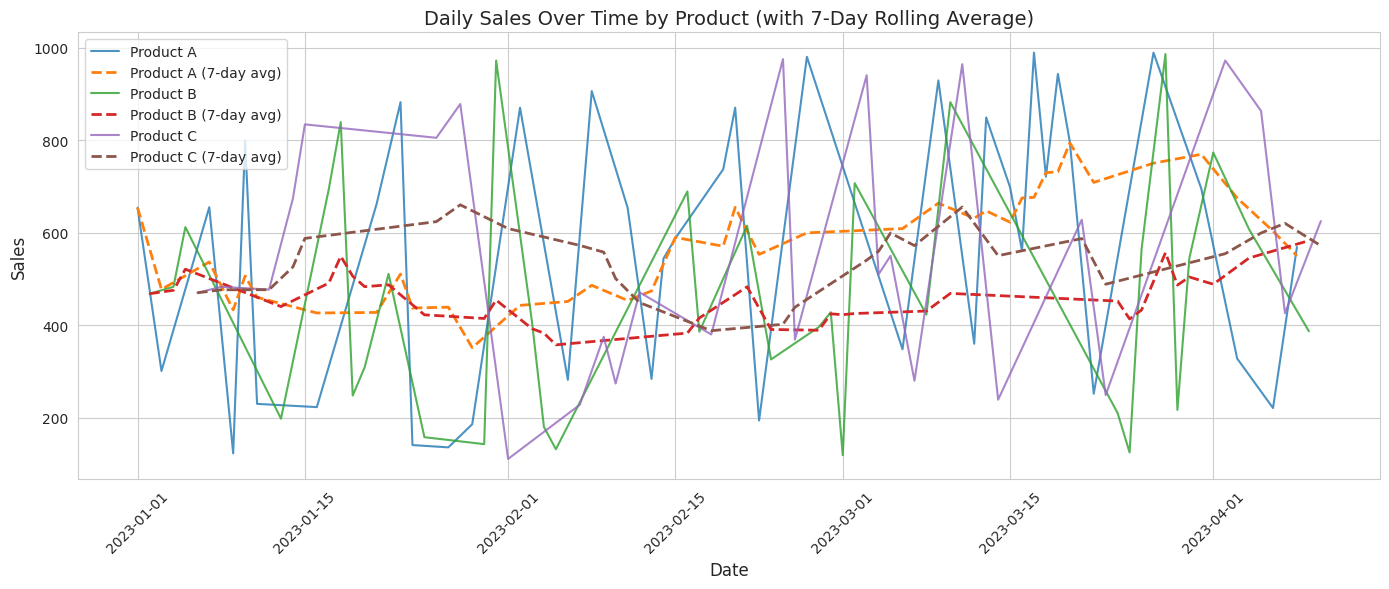

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is already created from the given data with 'Date' as datetime
df['Date'] = pd.to_datetime(df['Date'])

# Set style
sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))

# Plot sales over time for each product
for product in ['A', 'B', 'C']:
    subset = df[df['Product'] == product]
    ax.plot(subset['Date'], subset['Sales'], label=f'Product {product}', alpha=0.8, linewidth=1.5)
    # Add 7-day rolling mean to smooth the trend
    subset_sorted = subset.set_index('Date').sort_index()
    rolling_mean = subset_sorted['Sales'].rolling(window=7, min_periods=1).mean()
    ax.plot(rolling_mean.index, rolling_mean.values, label=f'Product {product} (7-day avg)',
            linestyle='--', linewidth=2)

# Formatting
ax.set_title('Daily Sales Over Time by Product (with 7-Day Rolling Average)', fontsize=14)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Sales', fontsize=12)
ax.legend(loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()